# Forecast 30 / 60 / 90 Days
Load the winning model, generate future-only forecasts, and export dashboard/API-ready CSV files.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
from ml.forecasting.forecast_service import ForecastService
import inspect
import ml.forecasting.forecast_service as forecast_module
import json
import pandas as pd

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("SRC_DIR:", SRC_DIR)

PROJECT_ROOT: d:\Research_Project\sales-forecasting-platform
SRC_DIR: d:\Research_Project\sales-forecasting-platform\src


In [2]:

decision_path = (
    PROJECT_ROOT
    / "artifacts"
    / "evaluation"
    / "final_model_decision.json"
)

with open(decision_path, "r", encoding="utf-8") as file:
    decision = json.load(file)

print(decision)
print("Selected model:", decision["selected_model"])

{'selected_model': 'Prophet', 'selection_rule': 'lowest validation RMSE; MAE tie-breaker', 'validation_MAE': 8096.651652607401, 'validation_RMSE': 10787.230116803275, 'test_MAE': 12334.488431530392, 'test_RMSE': 16838.06324087969, 'test_MAPE_pct': 29.92109202513373, 'test_R2': 0.5027893748132999, 'validation_RMSE_improvement_vs_naive_pct': 41.44421004695984, 'prophet_interval_coverage_pct': 69.38775510204081, 'prophet_average_interval_width': 29485.976784628238, 'mean_residual_bias': -1073.6589495067954, 'median_residual': -1954.1933925367957, 'residual_std': 16803.798087456533, 'negative_prediction_count': 2, 'test_observations': 98}
Selected model: Prophet


In [3]:
prophet_path = (
    PROJECT_ROOT
    / "artifacts"
    / "models"
    / "prophet_final.joblib"
)

print("Prophet artifact:", prophet_path)
print("Exists:", prophet_path.exists())

Prophet artifact: d:\Research_Project\sales-forecasting-platform\artifacts\models\prophet_final.joblib
Exists: True


In [4]:
## Initialize the reusable forecast service
service = ForecastService(PROJECT_ROOT)
print('Selected model:', service.model_name)
print('Last historical date:', service.history['date'].max())
print('Residual interval:', service.residual_low, service.residual_high)

Selected model: Prophet
Last historical date: 2011-12-09 00:00:00
Residual interval: -19211.424460909493 16409.861874312446


## Generate one recursive 90-day path

For ML models, each predicted value is appended to history before creating the next day's lag and rolling features. No future actual value is available or used.

In [5]:
forecast_90 = service.forecast(90)
forecast_30 = forecast_90.iloc[:30].copy()
forecast_60 = forecast_90.iloc[:60].copy()
assert len(forecast_30)==30 and len(forecast_60)==60 and len(forecast_90)==90
assert forecast_90['Date'].min() > service.history['date'].max()
assert forecast_90[['Forecast','Lower','Upper']].notna().all().all()
forecast_90.head()

,Date,Forecast,Lower,Upper,HorizonDay,Model,GeneratedFrom
0,2011-12-10,21368.703081,4943.482832,36171.574049,1,Prophet,2011-12-09
1,2011-12-11,36951.591590,22497.120255,54427.826356,2,Prophet,2011-12-09
2,2011-12-12,50352.918453,34154.321811,64922.113493,3,Prophet,2011-12-09
3,2011-12-13,50848.157894,35611.120739,67689.569872,4,Prophet,2011-12-09
4,2011-12-14,45206.108618,28358.280335,61199.795135,5,Prophet,2011-12-09


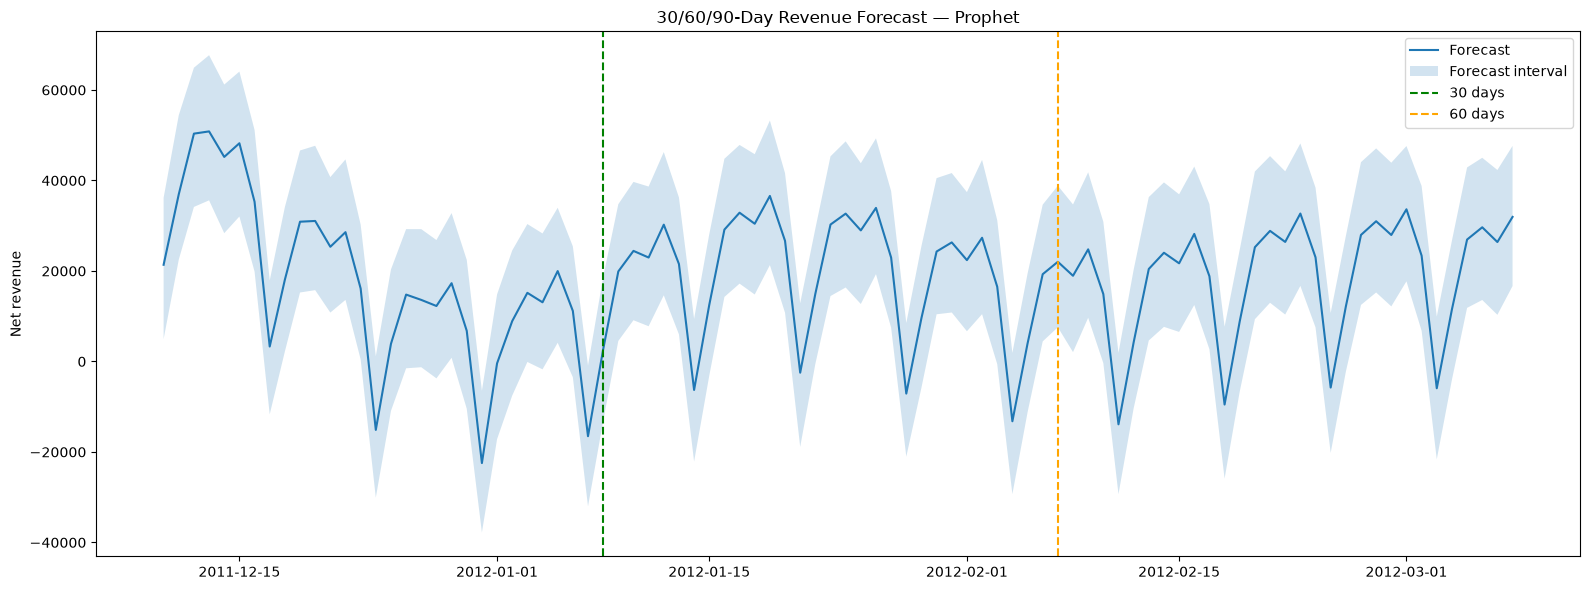

In [6]:
## Visualize forecast and uncertainty
plt.figure(figsize=(16,6))
plt.plot(forecast_90['Date'],forecast_90['Forecast'],label='Forecast',color='tab:blue')
plt.fill_between(forecast_90['Date'],forecast_90['Lower'],forecast_90['Upper'],alpha=.2,label='Forecast interval')
plt.axvline(forecast_30['Date'].max(),linestyle='--',color='green',label='30 days')
plt.axvline(forecast_60['Date'].max(),linestyle='--',color='orange',label='60 days')
plt.title(f"30/60/90-Day Revenue Forecast — {service.model_name}")
plt.ylabel('Net revenue'); 
plt.legend(); 
plt.tight_layout(); 
plt.show()

In [7]:
## Export the required CSV files
exported = service.export()
for horizon,path in exported.items():
    print(horizon, 'days ->', path)
pd.read_csv(exported[30]).head()

30 days -> D:\Research_Project\sales-forecasting-platform\artifacts\forecasts\forecast_30_days.csv
60 days -> D:\Research_Project\sales-forecasting-platform\artifacts\forecasts\forecast_60_days.csv
90 days -> D:\Research_Project\sales-forecasting-platform\artifacts\forecasts\forecast_90_days.csv


,Date,Forecast,Lower,Upper,HorizonDay,Model,GeneratedFrom
0,2011-12-10,21368.703081,6268.017559,37278.544943,1,Prophet,2011-12-09
1,2011-12-11,36951.591590,22350.160286,51746.156913,2,Prophet,2011-12-09
2,2011-12-12,50352.918453,34758.870606,66587.139064,3,Prophet,2011-12-09
3,2011-12-13,50848.157894,34963.321654,66192.208468,4,Prophet,2011-12-09
4,2011-12-14,45206.108618,28981.568393,60586.413192,5,Prophet,2011-12-09


In [8]:
## Produce a compact dashboard summary
summary_rows=[]
for horizon,frame in [(30,forecast_30),(60,forecast_60),(90,forecast_90)]:
    summary_rows.append(
        {
            'HorizonDays':horizon,
            'TotalForecastRevenue':frame.Forecast.sum(),
            'AverageDailyRevenue':frame.Forecast.mean(),
            'MinimumDailyForecast':frame.Forecast.min(),
            'MaximumDailyForecast':frame.Forecast.max(),
            'AverageIntervalWidth':(frame.Upper-frame.Lower).mean()
        })
forecast_summary=pd.DataFrame(summary_rows)
forecast_summary.to_csv(PROJECT_ROOT/'artifacts'/'forecasts'/'forecast_summary.csv',index=False)
forecast_summary.round(2)

,HorizonDays,TotalForecastRevenue,AverageDailyRevenue,MinimumDailyForecast,MaximumDailyForecast,AverageIntervalWidth
0,30,526693.02,17556.43,-22456.77,50848.16,31154.09
1,60,1120383.64,18673.06,-22456.77,50848.16,31065.84
2,90,1688935.34,18765.95,-22456.77,50848.16,31202.67


## FastAPI integration contract

Create one singleton `ForecastService` at application startup. `GET /api/forecast?days=30|60|90` returns `service.forecast(days)`. Do not reload the model for every request. Analytics endpoints should read cleaned historical data, not forecast CSVs: `/api/analytics/revenue`, `/growth`, `/top-products`, and `/categories`.

In [9]:
# Response shape expected by the future API
api_preview = {'model':service.model_name,'days':30,'generated_from':str(service.history['date'].max().date()),'forecasts':forecast_30.assign(Date=forecast_30.Date.dt.strftime('%Y-%m-%d')).to_dict(orient='records')}
list(api_preview.keys()), api_preview['forecasts'][:2]

(['model', 'days', 'generated_from', 'forecasts'],
 [{'Date': '2011-12-10',
   'Forecast': 21368.703081213236,
   'Lower': 4943.482831505735,
   'Upper': 36171.57404924528,
   'HorizonDay': 1,
   'Model': 'Prophet',
   'GeneratedFrom': Timestamp('2011-12-09 00:00:00')},
  {'Date': '2011-12-11',
   'Forecast': 36951.591589522315,
   'Lower': 22497.12025503125,
   'Upper': 54427.8263558315,
   'HorizonDay': 2,
   'Model': 'Prophet',
   'GeneratedFrom': Timestamp('2011-12-09 00:00:00')}])

## Completion criteria

The selected model comes from `final_model_decision.json`; dates start strictly after history; ML lag/rolling features use recursive predictions; Prophet uses native bounds while ML uses empirical residual bounds; 30/60/90 CSVs and `forecast_summary.csv` are saved; the service is reusable by FastAPI.

In [10]:
for horizon, frame in [
    (30, forecast_30),
    (60, forecast_60),
    (90, forecast_90)
]:
    negative = frame[frame["Forecast"] < 0]

    print(f"\n===== {horizon} DAYS =====")
    print(f"Total rows       : {len(frame)}")
    print(f"Negative rows    : {len(negative)}")
    print(f"Negative %       : {len(negative) / len(frame) * 100:.2f}%")
    print(f"Minimum forecast : {frame['Forecast'].min():,.2f}")
    print(f"Maximum forecast : {frame['Forecast'].max():,.2f}")
    print(f"Total forecast   : {frame['Forecast'].sum():,.2f}")


===== 30 DAYS =====
Total rows       : 30
Negative rows    : 4
Negative %       : 13.33%
Minimum forecast : -22,456.77
Maximum forecast : 50,848.16
Total forecast   : 526,693.02

===== 60 DAYS =====
Total rows       : 60
Negative rows    : 8
Negative %       : 13.33%
Minimum forecast : -22,456.77
Maximum forecast : 50,848.16
Total forecast   : 1,120,383.64

===== 90 DAYS =====
Total rows       : 90
Negative rows    : 12
Negative %       : 13.33%
Minimum forecast : -22,456.77
Maximum forecast : 50,848.16
Total forecast   : 1,688,935.34


In [11]:
for horizon, frame in [
    (30, forecast_30),
    (60, forecast_60),
    (90, forecast_90)
]:
    negative = frame[frame["Forecast"] < 0]

    print(f"\n===== NEGATIVE FORECAST: {horizon} DAYS =====")

    if negative.empty:
        print("No negative forecast.")
    else:
        display(
            negative[
                ["Date", "Forecast", "Lower", "Upper"]
            ].sort_values("Forecast")
        )


===== NEGATIVE FORECAST: 30 DAYS =====


,Date,Forecast,Lower,Upper
21,2011-12-31,-22456.772391,-37806.425637,-6482.304669
28,2012-01-07,-16518.357222,-32026.512109,-894.361494
14,2011-12-24,-15124.551642,-30101.263050,1151.396000
22,2012-01-01,-422.796880,-17179.526123,14806.867371



===== NEGATIVE FORECAST: 60 DAYS =====


,Date,Forecast,Lower,Upper
21,2011-12-31,-22456.772391,-37806.425637,-6482.304669
28,2012-01-07,-16518.357222,-32026.512109,-894.361494
14,2011-12-24,-15124.551642,-30101.263050,1151.396000
56,2012-02-04,-13213.672651,-29321.775027,1896.556924
49,2012-01-28,-7095.966759,-21040.611566,8510.091889
35,2012-01-14,-6293.894729,-22118.116327,9418.631553
42,2012-01-21,-2476.693852,-18879.430848,12868.608147
22,2012-01-01,-422.796880,-17179.526123,14806.867371



===== NEGATIVE FORECAST: 90 DAYS =====


,Date,Forecast,Lower,Upper
21,2011-12-31,-22456.772391,-37806.425637,-6482.304669
28,2012-01-07,-16518.357222,-32026.512109,-894.361494
14,2011-12-24,-15124.551642,-30101.263050,1151.396000
63,2012-02-11,-13889.210891,-29331.198515,1917.389048
56,2012-02-04,-13213.672651,-29321.775027,1896.556924
70,2012-02-18,-9519.758727,-25891.337788,7676.610034
49,2012-01-28,-7095.966759,-21040.611566,8510.091889
35,2012-01-14,-6293.894729,-22118.116327,9418.631553
84,2012-03-03,-5923.216723,-21625.671225,9913.103825
77,2012-02-25,-5762.928995,-20200.954640,10722.153523


In [12]:
for horizon, frame in [
    (30, forecast_30),
    (60, forecast_60),
    (90, forecast_90)
]:
    total = frame["Forecast"].sum()

    print(
        f"{horizon} days total forecast revenue: "
        f"{total:,.2f}"
    )

30 days total forecast revenue: 526,693.02
60 days total forecast revenue: 1,120,383.64
90 days total forecast revenue: 1,688,935.34


In [13]:
validation_rows = []

for horizon, frame in [
    (30, forecast_30),
    (60, forecast_60),
    (90, forecast_90)
]:
    forecast = frame["Forecast"]

    validation_rows.append({
        "HorizonDays": horizon,
        "Rows": len(frame),
        "TotalForecastRevenue": forecast.sum(),
        "AverageDailyRevenue": forecast.mean(),
        "MinimumDailyForecast": forecast.min(),
        "MaximumDailyForecast": forecast.max(),
        "NegativeForecastCount": (forecast < 0).sum(),
        "NegativeForecastPct": (forecast < 0).mean() * 100,
        "NegativeForecastSum": forecast[forecast < 0].sum()
    })

validation_df = pd.DataFrame(validation_rows)

display(validation_df.round(2))

,HorizonDays,Rows,TotalForecastRevenue,AverageDailyRevenue,MinimumDailyForecast,MaximumDailyForecast,NegativeForecastCount,NegativeForecastPct,NegativeForecastSum
0,30,30,526693.02,17556.43,-22456.77,50848.16,4,13.33,-54522.48
1,60,60,1120383.64,18673.06,-22456.77,50848.16,8,13.33,-83602.71
2,90,90,1688935.34,18765.95,-22456.77,50848.16,12,13.33,-118697.82
